# P3 프로젝트: EuroSAT 위성영상 분류

**프로젝트 목표**는 64×64 RGB 위성영상에서 토지 이용·피복 유형 **10개 중 하나**를 예측하는 CNN을 만들고, **모델을 비교·검증·해석하여 최종 선택의 근거를 제시하는 것**이다.

전체 **27,000장**을 모두 사용한다. 훈련·검증·테스트로 나누더라도 데이터를 버리거나 일부 클래스만 선택하지 않는다.

이번 프로젝트는 CNN을 처음부터 학습하는 방법과 사전훈련된 Xception을 활용하는 방법을 다룬다. **Keras와 PyTorch를 모두 사용**하고, 두 프레임워크에서 동일한 데이터 분할과 클래스 번호를 유지한다.

> **프로젝트 흐름:** 문제 이해 → 데이터 확인 → 공통 분할 → 기준 모델 → 데이터 증식/구조 개선 → Xception 전이 학습·미세 조정 → 검증 비교 → 테스트 평가 → 오분류 분석 → 결론

**코드 실행**

[(구글 코랩) P3 프로젝트: EuroSAT 위성영산 분류](https://colab.research.google.com/github/codingalzi/code-workout-dlp/blob/master/P3_project_eurosat.ipynb)에서 코드를 실행할 수 있다.

## 프로젝트에서 해야 할 일

1. EuroSAT의 클래스, 입력 이미지, 데이터 개수를 확인한다.
2. 전체 27,000장을 **훈련 18,900 / 검증 4,050 / 테스트 4,050**으로 계층화 분할한다.
3. **Keras 기준 CNN과 데이터 증식 CNN**의 훈련·검증 성능을 비교한다.
4. **Keras Xception 전이 학습 및 미세 조정**을 수행하고, 개선 여부를 검증 데이터로 판단한다.
5. **PyTorch 기준 CNN과 개선 CNN**을 구현하고 비교한다. 개선 모델에는 채널 분리 합성곱·배치 정규화·잔차 연결을 활용할 수 있다.
6. 프레임워크별 최종 모델을 **검증 성능만으로 선택**한 다음, 선택된 모델을 테스트 데이터에서 평가한다.
7. 혼동행렬, 클래스별 성능, 오분류 이미지를 살펴보고 모델의 한계를 설명한다.
8. 실험 조건과 생성형 AI 활용·검증 과정을 기록한다.

**평가의 핵심:** 가장 높은 정확도 하나를 만드는 것보다 **비교 조건이 타당한지, 테스트 데이터를 보호했는지, 모델의 판단을 설명할 수 있는지**가 중요하다.

## 생성형 AI 활용

생성형 AI를 코드 작성·수정, Keras↔PyTorch 변환, 오류 해석, 그래프 및 평가 코드 작성에 활용해도 된다. 그러나 **데이터 분할, 입력 전처리, 클래스 번호, 모델 출력과 손실함수의 대응, 실험 조건, 평가 방법과 결론**은 직접 확인해야 한다.

실험을 수행한 뒤에는 **AI가 제안한 내용 중 실제로 검증한 것**을 보고서에 구체적으로 기록한다.

---

## 1. 실행 준비

데이터는 프로젝트 폴더의 `datasets/`에 다운로드하여 재사용한다. `torchvision.datasets.EuroSAT`는 RGB 이미지를 제공한다. 처음 다운로드할 때만 인터넷이 필요하다.

필요한 패키지: `tensorflow`, `keras`, `torch`, `torchvision`, `scikit-learn`, `matplotlib`, `pandas`, `Pillow`.

설치하지 않은 패키지가 있다면 노트북 환경에 맞게 설치한 후 커널을 재시작한다. TensorFlow와 PyTorch의 GPU 지원 여부는 환경에 따라 다르다.

**실행 부담:** 전체 이미지 27,000장을 사용하므로 특히 Xception은 GPU 실행을 권장한다. 개인 PC의 사양에 따라 에포크 수와 배치 크기는 조절해도 되지만 **데이터 개수나 분할은 변경하지 않는다.**

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

from pathlib import Path
from copy import deepcopy
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
import keras
from keras import layers
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
torch.manual_seed(SEED)

DATA_ROOT = Path("datasets")
OUTPUT_ROOT = Path("p3_eurosat_outputs")
DATA_ROOT.mkdir(exist_ok=True, parents=True)
OUTPUT_ROOT.mkdir(exist_ok=True, parents=True)

print("Keras:", keras.__version__, "TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("TensorFlow GPU:", tf.config.list_physical_devices("GPU"))
print("PyTorch GPU:", torch.cuda.is_available())

Keras: 3.13.2 TensorFlow: 2.20.0
PyTorch: 2.10.0+cu128
TensorFlow GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch GPU: True


### 실행 스위치

모델 훈련은 시간이 걸리므로 아래 스위치는 기본적으로 꺼져 있다. **해당 절을 실행할 때 `True`로 바꾼 뒤 관련 셀을 실행**한다. 데이터 준비와 분할, 시각화는 스위치와 관계없이 실행된다.

**권장 순서:** Keras 기준 → Keras 증식 → Xception 전이 학습 → Xception 미세 조정 → PyTorch 기준 → PyTorch 개선 → 최종 평가.

In [2]:
RUN_KERAS_BASELINE = False
RUN_KERAS_AUGMENTED = False
RUN_XCEPTION_TRANSFER = False
RUN_XCEPTION_FINE_TUNING = False
RUN_TORCH_BASELINE = False
RUN_TORCH_IMPROVED = False
RUN_FINAL_TEST = False     # 검증 비교가 끝난 뒤에만 True

KERAS_BATCH_SIZE = 64
XCEPTION_BATCH_SIZE = 16
TORCH_BATCH_SIZE = 64
BASELINE_EPOCHS = 5
TRANSFER_EPOCHS = 4
FINE_TUNE_EPOCHS = 2
TORCH_EPOCHS = 5

---

## 2. EuroSAT 데이터 탐색

EuroSAT RGB는 Sentinel-2 영상으로 만든 **64×64×3 위성영상 27,000장**으로 구성된다. 클래스는 총 10개이며 각 이미지의 정답은 **해당 영상의 대표적인 토지 이용·피복 유형**이다.

주의: **RGB 버전**과 13개 밴드의 다중분광 버전은 다르다. 이 프로젝트는 RGB만 사용한다. 또한 원본 데이터에는 별도로 지정된 훈련·검증·테스트 분할이 없으므로 직접 분할한다.

데이터 출처: [EuroSAT 원저자 저장소](https://github.com/phelber/eurosat), [TorchVision EuroSAT](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.EuroSAT.html), [TensorFlow Datasets EuroSAT](https://www.tensorflow.org/datasets/catalog/eurosat)

In [3]:
# 이미 내려받은 파일이 있으면 다시 다운로드하지 않는다.
eurosat = datasets.EuroSAT(root=str(DATA_ROOT), download=True)

class_names = list(eurosat.classes)
image_paths = np.asarray([path for path, _ in eurosat.samples])
labels = np.asarray(eurosat.targets, dtype=np.int64)
num_classes = len(class_names)

print("Total images:", len(eurosat))
print("Number of classes:", num_classes)
print("Classes:", class_names)
print("First image:", image_paths[0])

assert len(eurosat) == 27000, "EuroSAT RGB 전체 27,000장을 읽었는지 확인하세요."
assert num_classes == 10

100%|██████████| 94.3M/94.3M [00:04<00:00, 23.2MB/s]


Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
First image: datasets/eurosat/2750/AnnualCrop/AnnualCrop_1.jpg


### 이미지 관찰

각 클래스에서 **훈련 이미지**를 1장씩 골라서 확인한다. 따라서 아래 이미지는 원본 데이터의 예시이지만 아직 평가에 사용할 테스트 이미지는 사용하지 않는다.

1. 비슷한 질감이나 형태 때문에 구분하기 어려운 클래스는 무엇인가?
2. 일반 사진과 비교하면 객체의 위치·크기·방향이 어떻게 다른가?
3. 이 문제에서 CNN의 공간적 특징 추출은 왜 유용할까?

---

## 3. 공통 훈련·검증·테스트 분할

전체 27,000장을 70% / 15% / 15%로 분할한다. 각 클래스의 비율이 가능한 한 유지되도록 **계층화 분할(stratified split)**을 사용한다. Keras와 PyTorch는 **똑같은 인덱스**를 사용한다.

- 훈련 데이터: 모델 가중치를 학습한다.
- 검증 데이터: 모델과 하이퍼파라미터를 선택한다.
- 테스트 데이터: **모델 선택이 끝난 다음 최종 성능을 확인한다.**

위성영상은 지리적으로 가까운 이미지끼리 유사할 수 있다. 이번 무작위 분할 결과를 **새로운 지역으로의 일반화 성능**이라고 그대로 해석해서는 안 된다. 원본 분할에 지리적 구분 정보가 충분히 포함되지 않을 수 있다는 한계를 기록한다.

In [4]:
# 데이터 목록 자체가 바뀌면 예전에 저장한 분할을 잘못 재사용하지 않도록 확인한다.
source_signature = hashlib.sha256(
    "\n".join(str(Path(p).relative_to(DATA_ROOT)) for p in image_paths).encode("utf-8")
).hexdigest()

split_path = OUTPUT_ROOT / "eurosat_split_seed42.npz"
if split_path.exists():
    with np.load(split_path) as saved:
        assert str(saved["signature"].item()) == source_signature, "데이터 순서가 변경되었습니다. 분할 파일을 확인하세요."
        train_idx = saved["train_idx"]
        val_idx = saved["val_idx"]
        test_idx = saved["test_idx"]
else:
    indices = np.arange(len(labels))
    train_idx, remain_idx = train_test_split(
        indices, train_size=0.70, stratify=labels, random_state=SEED
    )
    val_idx, test_idx = train_test_split(
        remain_idx, test_size=0.50, stratify=labels[remain_idx], random_state=SEED
    )
    np.savez(split_path, train_idx=train_idx, val_idx=val_idx,
             test_idx=test_idx, signature=source_signature)

assert len(train_idx) == 18900 and len(val_idx) == 4050 and len(test_idx) == 4050
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(labels)
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

print("Train / Validation / Test:", len(train_idx), len(val_idx), len(test_idx))

Train / Validation / Test: 18900 4050 4050


,Train,Validation,Test
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375
SeaLake,2100,450,450


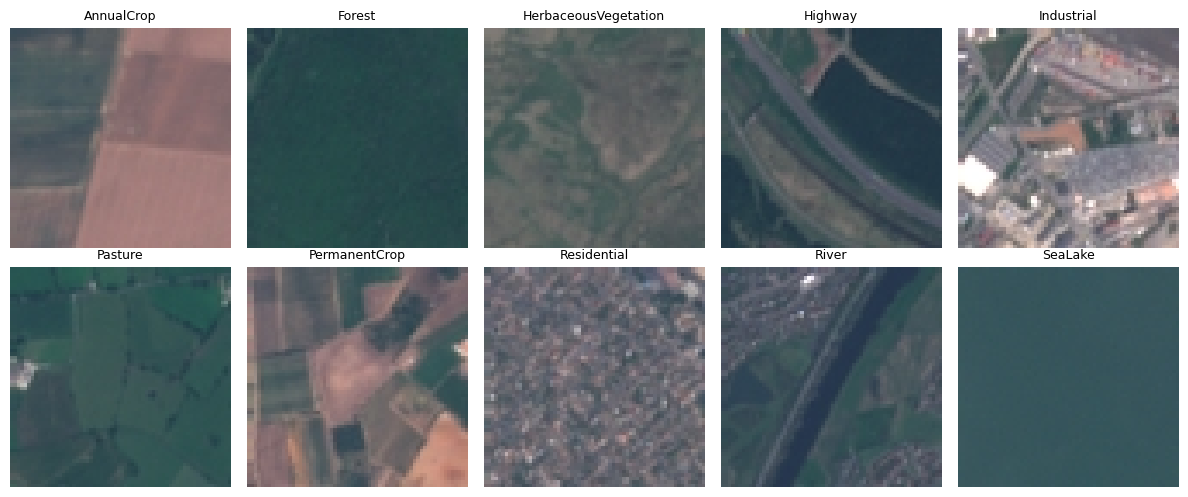

In [5]:
counts = pd.DataFrame({
    "Train": np.bincount(labels[train_idx], minlength=num_classes),
    "Validation": np.bincount(labels[val_idx], minlength=num_classes),
    "Test": np.bincount(labels[test_idx], minlength=num_classes),
}, index=class_names)
display(counts)

# 각 클래스의 훈련 이미지를 한 장씩 표시한다.
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    image_idx = next(i for i in train_idx if labels[i] == class_id)
    with Image.open(image_paths[image_idx]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(class_names[class_id], fontsize=9)
    ax.axis("off")
plt.tight_layout()

### 데이터 이해 — 답안

1. 각 이미지의 입력 모양과 타깃의 의미는 무엇인가?
2. 이미지가 27,000장인데, 왜 훈련에 18,900장만 사용하는가?
3. 클래스별 데이터 개수에 차이가 있는가? 있다면 어떤 평가 지표가 추가로 필요할까?
4. 위성영상의 **회전·좌우 반전·상하 반전**이 학습에 적절할지 예측하고, 그 근거를 쓰자.

**답:**

> 여기에 관찰과 해석을 작성한다.

---

## 4. 공통 전처리와 입력 형식

- Keras 이미지 입력: `(N, H, W, C)` (NHWC)
- PyTorch 이미지 입력: `(N, C, H, W)` (NCHW)
- **기준 CNN:** 원래의 64×64 RGB 이미지를 `[0,1]`로 정규화
- **Xception:** 입력을 96×96으로 리사이즈하고 `[-1,1]`로 정규화

검증·테스트 데이터에는 **무작위 증식을 적용하지 않는다.** 이미지 크기를 바꾸는 처리와 픽셀값 정규화는 평가 데이터에도 같은 방식으로 적용해야 한다.

### Keras 입력 파이프라인

JPEG 이미지 파일의 경로를 이용해 배치 단위로 읽는다. 전체 이미지를 미리 `float32` 배열로 복사하지 않으므로 메모리 사용을 줄일 수 있다.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_image(path, label):
    content = tf.io.read_file(path)
    image = tf.io.decode_jpeg(content, channels=3)
    image = tf.image.resize(image, [64, 64])
    return tf.cast(image, tf.float32), tf.cast(label, tf.int32)  # 아직 [0,255]


def make_keras_dataset(indices, batch_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices((image_paths[indices], labels[indices]))
    if training:
        ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    return (ds.map(decode_image, num_parallel_calls=AUTOTUNE)
              .batch(batch_size).prefetch(AUTOTUNE))

keras_train_ds = make_keras_dataset(train_idx, KERAS_BATCH_SIZE, training=True)
keras_val_ds = make_keras_dataset(val_idx, KERAS_BATCH_SIZE)
keras_test_ds = make_keras_dataset(test_idx, KERAS_BATCH_SIZE)

example_images, example_labels = next(iter(keras_train_ds))
print("Keras batch:", example_images.shape, example_labels.shape)
print("Pixel range:", float(tf.reduce_min(example_images)), float(tf.reduce_max(example_images)))

I0000 00:00:1793504013.986439   16340 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8855 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:01:00.0, compute capability: 8.9


Keras batch: (64, 64, 64, 3) (64,)
Pixel range: 18.0 255.0


### PyTorch 입력 파이프라인

이미지 파일과 인덱스는 Keras와 동일하다. `ToTensor()`가 `[0,1]`로 바꾸고 채널을 첫 번째 축으로 이동시킨다. Windows 환경에서도 실행하기 쉽도록 `num_workers=0`을 기본으로 사용한다.

In [7]:
plain_transform = transforms.ToTensor()
aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(90),
    transforms.ToTensor(),
])

# 기준 모델과 개선 모델을 구조 중심으로 비교하기 위해 우선 동일한 전처리를 사용한다.
# 추가 실험에서 aug_transform을 적용할 수 있다.
torch_data_plain = datasets.EuroSAT(root=str(DATA_ROOT), download=False,
                                    transform=plain_transform)

train_torch_ds = Subset(torch_data_plain, train_idx.tolist())
val_torch_ds = Subset(torch_data_plain, val_idx.tolist())
test_torch_ds = Subset(torch_data_plain, test_idx.tolist())

pin_memory = torch.cuda.is_available()
train_loader = DataLoader(train_torch_ds, batch_size=TORCH_BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=pin_memory)
val_loader = DataLoader(val_torch_ds, batch_size=TORCH_BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=pin_memory)
test_loader = DataLoader(test_torch_ds, batch_size=TORCH_BATCH_SIZE,
                         shuffle=False, num_workers=0, pin_memory=pin_memory)

torch_x, torch_y = next(iter(train_loader))
print("PyTorch batch:", tuple(torch_x.shape), tuple(torch_y.shape))
print("Pixel range:", torch_x.min().item(), torch_x.max().item())

PyTorch batch: (64, 3, 64, 64) (64,)
Pixel range: 0.0784313753247261 1.0


### 전처리 확인 — 답안

1. Keras와 PyTorch 입력 텐서의 차원 순서는 어떻게 다른가?
2. Xception에 기준 CNN의 `[0,1]` 정규화 값을 그대로 입력하면 어떤 문제가 생기는가?
3. 데이터 증식은 왜 훈련 데이터에만 적용하는가?

**답:**

> 여기에 설명을 작성한다.

---

## 5. Keras: 기준 CNN

기준 모델에서는 **Conv2D → MaxPooling2D → GlobalAveragePooling2D → Dense(10, softmax)** 구조를 사용한다. 손실함수는 `sparse_categorical_crossentropy`이며, 정답은 정수 클래스 번호 `0~9`다.

우선 이 모델의 훈련·검증 곡선을 보고 과소적합이나 과대적합이 있는지 판단한다.

In [8]:
def build_keras_cnn(use_augmentation=False):
    inputs = keras.Input(shape=(64, 64, 3))
    x = inputs
    if use_augmentation:
        x = layers.RandomFlip("horizontal_and_vertical")(x)
        x = layers.RandomRotation(0.25, fill_mode="reflect")(x)
    x = layers.Rescaling(1.0 / 255.0)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

keras_base = build_keras_cnn(use_augmentation=False)
keras_base.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,538 (369.29 KB)

 Trainable params: 94,538 (369.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# 훈련된 Keras 모델의 검증 성능과 체크포인트 경로를 보관한다.
keras_records = {}

def train_keras_model(model, name, train_ds, val_ds, epochs, batch_size_note):
    model_path = OUTPUT_ROOT / (name + ".keras")
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                      restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(model_path), monitor="val_loss",
                                        save_best_only=True),
    ]
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=callbacks, verbose=1)
    best_epoch = int(np.argmin(history.history["val_loss"]))
    keras_records[name] = {
        "val_loss": float(history.history["val_loss"][best_epoch]),
        "val_accuracy": float(history.history["val_accuracy"][best_epoch]),
        "best_epoch": best_epoch + 1,
        "path": str(model_path),
        "history": history.history,
        "batch_size": batch_size_note,
    }
    return history

if RUN_KERAS_BASELINE:
    keras.utils.set_random_seed(SEED)
    keras_base = build_keras_cnn(False)
    keras_base_history = train_keras_model(
        keras_base, "keras_baseline", keras_train_ds, keras_val_ds,
        BASELINE_EPOCHS, KERAS_BATCH_SIZE
    )
else:
    print("Keras 기준 모델을 훈련하려면 RUN_KERAS_BASELINE=True")

Keras 기준 모델을 훈련하려면 RUN_KERAS_BASELINE=True


### 결과 관찰

- 학습 에포크가 증가하면서 훈련 손실과 검증 손실은 각각 어떻게 변했는가?
- 기준 CNN의 검증 성능이 충분한가? 판단의 근거는 무엇인가?
- 모델의 출력층과 손실함수가 다중 클래스 분류에 맞게 설정되었는가?

**답:**

> 여기에 작성한다.

---

## 6. Keras: 데이터 증식 CNN

기준 모델과 **합성곱 구조·학습률·에포크·데이터 분할은 같게** 두고, 훈련 시 적용하는 이미지 증식만 추가한다. 이는 증식 자체의 효과를 비교하기 위한 실험이다.

위성영상은 방향에 따라 클래스가 달라지지 않는 경우가 많으므로 좌우·상하 반전과 회전을 먼저 시도한다. 다만 **회전·보간에 따른 손실**이나 경계가 잘리는 문제는 직접 확인해야 한다.

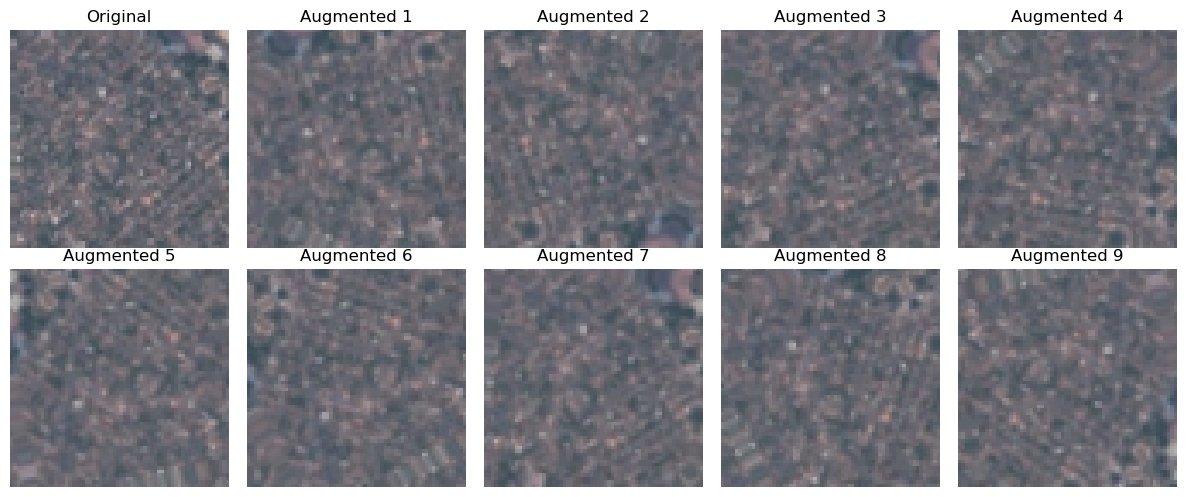

In [10]:
# 실제 증식 이미지와 원본 이미지를 비교한다.
example_path = image_paths[train_idx[0]]
with Image.open(example_path) as img:
    original = np.asarray(img.convert("RGB"), dtype=np.float32)

visual_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25, fill_mode="reflect"),
])
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flat
axes[0].imshow(original.astype("uint8"))
axes[0].set_title("Original")
for i, ax in enumerate(list(axes)[1:], 1):
    augmented = visual_augmentation(original[None, ...], training=True).numpy()[0]
    ax.imshow(np.clip(augmented, 0, 255).astype("uint8"))
    ax.set_title(f"Augmented {i}")
for ax in fig.axes:
    ax.axis("off")
plt.tight_layout()

In [11]:
if RUN_KERAS_AUGMENTED:
    keras.utils.set_random_seed(SEED)
    keras_augmented = build_keras_cnn(use_augmentation=True)
    keras_aug_history = train_keras_model(
        keras_augmented, "keras_augmented", keras_train_ds, keras_val_ds,
        BASELINE_EPOCHS, KERAS_BATCH_SIZE
    )
else:
    print("Keras 증식 모델을 훈련하려면 RUN_KERAS_AUGMENTED=True")

Keras 증식 모델을 훈련하려면 RUN_KERAS_AUGMENTED=True


### 증식 효과 판단 — 답안

1. 기준 CNN과 증식 CNN의 검증 손실·정확도를 비교하면 어떤 차이가 나타나는가?
2. 훈련 정확도가 낮아졌더라도 검증 정확도가 높아졌다면 어떻게 해석해야 하는가?
3. 회전과 반전이 항상 성능을 높이는가? **결과에 근거하여** 답하자.

**답:**

> 여기에 작성한다.

---

## 7. Keras: Xception 전이 학습

Xception은 채널 분리 합성곱·배치 정규화·잔차 연결을 사용하는 CNN이다. 여기서는 **ImageNet 사전훈련 특성 추출기**를 동결하고 새로운 **10클래스 분류층**을 학습한다.

- `include_top=False`: ImageNet의 기존 분류층 제외
- `weights="imagenet"`: 사전훈련 가중치 사용
- `base.trainable=False`: Xception 기저 동결
- `base(x, training=False)`: 기저의 BatchNormalization을 추론 모드로 유지
- `Resizing(96, 96)`: 64×64 이미지를 Xception이 처리할 수 있도록 크기 조정
- `Rescaling(1/127.5, offset=-1)`: `[0,255] → [-1,1]`

**실행 판단:** Xception은 큰 모델이다. GPU가 없다면 전체 데이터의 에포크 수를 최소화하되, 실험에 사용한 에포크 수와 계산 환경을 기록한다. **테스트 성능으로 학습률이나 에포크를 조정하지 않는다.**

In [12]:
def build_xception_transfer():
    base = keras.applications.Xception(
        include_top=False, weights="imagenet", input_shape=(96, 96, 3)
    )
    base.trainable = False

    inputs = keras.Input(shape=(64, 64, 3))
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.25, fill_mode="reflect")(x)
    x = layers.Resizing(96, 96)(x)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="eurosat_xception")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base

xception_model, xception_base = None, None
if RUN_XCEPTION_TRANSFER:
    keras.utils.set_random_seed(SEED)
    xception_model, xception_base = build_xception_transfer()
    xception_model.summary()
    xception_train_ds = make_keras_dataset(train_idx, XCEPTION_BATCH_SIZE, training=True)
    xception_val_ds = make_keras_dataset(val_idx, XCEPTION_BATCH_SIZE)
    xception_history = train_keras_model(
        xception_model, "xception_transfer", xception_train_ds, xception_val_ds,
        TRANSFER_EPOCHS, XCEPTION_BATCH_SIZE
    )
else:
    print("전이 학습을 시작하려면 RUN_XCEPTION_TRANSFER=True")

전이 학습을 시작하려면 RUN_XCEPTION_TRANSFER=True


### 전이 학습의 효과 — 답안

1. 처음부터 훈련한 CNN과 Xception 전이 학습의 **검증 손실과 정확도**는 어떻게 다른가?
2. ImageNet 자연 사진과 EuroSAT 위성영상은 어떤 점에서 다른가?
3. 전이 학습이 더 좋거나 나쁜 결과를 보였다면 어떤 이유를 고려해야 하는가?

**답:**

> 여기에 비교와 근거를 작성한다.

---

## 8. Keras: Xception 미세 조정

전이 학습에서 분류층을 학습한 뒤, Xception의 **마지막 일부 층만 동결 해제**하여 작은 학습률로 추가 훈련한다.

1. 전이 학습이 끝난 모델을 준비한다.
2. 마지막 일부 층을 제외한 나머지를 동결한다.
3. 모든 BatchNormalization 층은 계속 동결한다.
4. **모델을 다시 compile**하고 `1e-5` 등 작은 학습률로 훈련한다.
5. 전이 학습만 한 모델과 **같은 검증 데이터**에서 비교한다.

미세 조정은 이전 결과를 항상 개선하는 것은 아니다. 전이 학습 모델은 별도 파일로 보존한다.

In [13]:
if RUN_XCEPTION_FINE_TUNING:
    assert RUN_XCEPTION_TRANSFER and xception_model is not None, (
        "전이 학습 셀을 먼저 실행하세요."
    )
    xception_base.trainable = True
    for layer in xception_base.layers[:-20]:
        layer.trainable = False
    for layer in xception_base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    print("Trainable weights in base:", len(xception_base.trainable_weights))
    xception_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                           loss="sparse_categorical_crossentropy",
                           metrics=["accuracy"])
    finetune_history = train_keras_model(
        xception_model, "xception_finetuned", xception_train_ds, xception_val_ds,
        FINE_TUNE_EPOCHS, XCEPTION_BATCH_SIZE
    )
else:
    print("미세 조정은 RUN_XCEPTION_FINE_TUNING=True로 변경한 뒤 실행하세요.")

미세 조정은 RUN_XCEPTION_FINE_TUNING=True로 변경한 뒤 실행하세요.


### 미세 조정의 효과 — 답안

1. 동결 해제한 층과 학습률을 어떻게 설정했는가?
2. 전이 학습만 한 모델과 미세 조정 모델에서 검증 손실은 어떻게 달라졌는가?
3. BatchNormalization을 동결한 이유는 무엇인가?
4. 미세 조정이 유리하지 않았다면 어떤 결론을 내릴 수 있는가?

**답:**

> 여기에 작성한다.

---

## 9. Keras 모델 검증 비교

모델을 선택하는 기준을 **검증 손실 최소**로 통일한다. 최고 검증 정확도도 함께 확인하지만, **테스트 데이터를 이용해 선택하지 않는다.**

In [14]:
def plot_training_history(history, title):
    n = len(history["loss"])
    epochs = np.arange(1, n + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for key, ax, label in [("loss", axes[0], "Loss"),
                           ("accuracy", axes[1], "Accuracy")]:
        ax.plot(epochs, history[key], marker="o", label="Train")
        ax.plot(epochs, history["val_" + key], marker="o", label="Validation")
        ax.set(xlabel="Epoch", ylabel=label, title=f"{title}: {label}")
        ax.set_xticks(np.arange(1, n + 1, max(1, int(np.ceil(n / 20)))))
        ax.legend()
    plt.tight_layout()

if keras_records:
    rows = [{"Model": name, "Best val loss": rec["val_loss"],
             "Val accuracy": rec["val_accuracy"], "Best epoch": rec["best_epoch"]}
            for name, rec in keras_records.items()]
    display(pd.DataFrame(rows).sort_values("Best val loss"))
    for name, rec in keras_records.items():
        plot_training_history(rec["history"], name)
else:
    print("Keras 모델을 훈련한 뒤 검증 결과를 비교하세요.")

Keras 모델을 훈련한 뒤 검증 결과를 비교하세요.


### Keras 모델 선택 — 답안

- 기준 모델과 비교 모델의 **변경 요소**를 정리하자.
- 어떤 모델이 검증 손실이 가장 낮았는가?
- 실험 간 학습 에포크·전처리·학습률·사전훈련 여부는 어떻게 달랐는가?
- 복잡한 모델의 추가 계산 비용이 정당화되는가?

**Keras 최종 선택 모델:**

**선택 이유:**

> 여기에 작성한다.

---

## 10. PyTorch: 기준 CNN

Keras와 **같은 데이터·클래스·분할**을 사용하지만, 입력은 `(N,3,64,64)`이고 모델은 **logits**를 출력한다. 따라서 `nn.CrossEntropyLoss()`를 사용한다.

코드 작성 자체보다 모델의 출력·손실함수와 평가가 올바른지 판단하는 데 집중한다.

In [15]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class TorchBaselineCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.classifier(x)  # logits: (batch, 10)

torch_base = TorchBaselineCNN(num_classes).to(DEVICE)
with torch.no_grad():
    print("Output shape:", tuple(torch_base(torch.zeros(2, 3, 64, 64, device=DEVICE)).shape))
print("Parameters:", sum(p.numel() for p in torch_base.parameters()))

Output shape: (2, 10)
Parameters: 94538


In [16]:
def run_torch_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_fn = nn.CrossEntropyLoss()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


torch_records = {}

def train_torch_model(model, name, epochs=5, learning_rate=1e-3):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    for epoch in range(epochs):
        train_loss, train_acc = run_torch_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_torch_epoch(model, val_loader)
        for key, value in [("loss", train_loss), ("accuracy", train_acc),
                           ("val_loss", val_loss), ("val_accuracy", val_acc)]:
            history[key].append(float(value))
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            best_epoch = epoch + 1
        print(f"Epoch {epoch + 1}/{epochs} | train={train_loss:.3f}, {train_acc:.3f} | "
              f"val={val_loss:.3f}, {val_acc:.3f}")
    model.load_state_dict(best_state)
    save_path = OUTPUT_ROOT / f"{name}.pt"
    torch.save(best_state, save_path)
    torch_records[name] = {"model": model, "path": str(save_path),
                           "val_loss": best_val_loss,
                           "val_accuracy": history["val_accuracy"][best_epoch - 1],
                           "best_epoch": best_epoch, "history": history}
    return model, history

if RUN_TORCH_BASELINE:
    torch.manual_seed(SEED)
    torch_base = TorchBaselineCNN(num_classes)
    torch_base, torch_base_history = train_torch_model(
        torch_base, "torch_baseline", TORCH_EPOCHS
    )
else:
    print("PyTorch 기준 모델을 훈련하려면 RUN_TORCH_BASELINE=True")

PyTorch 기준 모델을 훈련하려면 RUN_TORCH_BASELINE=True


---

## 11. PyTorch: 개선 CNN (Mini Xception)

배치 정규화·잔차 연결·채널 분리 합성곱을 결합한 **간소화된 Xception**을 사용한다. 원래 Xception을 완전히 재현한 모델이 아니며 **사전훈련 가중치 없이 처음부터 훈련**한다.

비교의 핵심은 더 복잡한 구조가 항상 더 좋은지 확인하는 것이다. 아래에서는 구조 변경의 효과를 보려고 **기준 모델과 같은 데이터 증식 없는 입력, 같은 에포크, 같은 손실함수**를 사용한다.

In [17]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, 3, padding=1,
                                   groups=in_channels, bias=False)
        self.pointwise = nn.Conv2d(in_channels, out_channels, 1, bias=False)

    def forward(self, x):
        return self.pointwise(self.depthwise(x))


class MiniXceptionBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.ReLU(),
            DepthwiseSeparableConv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            DepthwiseSeparableConv(out_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.MaxPool2d(3, stride=2, padding=1) if stride == 2 else nn.Identity(),
        )
        self.skip = (nn.Identity() if stride == 1 and in_channels == out_channels
                     else nn.Sequential(nn.Conv2d(in_channels, out_channels, 1,
                                                  stride=stride, bias=False),
                                        nn.BatchNorm2d(out_channels)))

    def forward(self, x):
        return self.main(x) + self.skip(x)


class MiniXception(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 24, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(24), nn.ReLU())
        self.entry = MiniXceptionBlock(24, 32, stride=2)
        self.middle = MiniXceptionBlock(32, 32)
        self.exit = MiniXceptionBlock(32, 64, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Linear(64, n_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.entry(x)
        x = self.middle(x)
        x = self.exit(x)
        return self.head(self.pool(x).flatten(1))

mini_xception = MiniXception(num_classes).to(DEVICE)
with torch.no_grad():
    print("Output shape:", tuple(mini_xception.eval()(torch.zeros(2, 3, 64, 64, device=DEVICE)).shape))
print("Parameters:", sum(p.numel() for p in mini_xception.parameters()))

Output shape: (2, 10)
Parameters: 16794


In [18]:
if RUN_TORCH_IMPROVED:
    torch.manual_seed(SEED)
    mini_xception = MiniXception(num_classes)
    mini_xception, mini_history = train_torch_model(
        mini_xception, "torch_mini_xception", TORCH_EPOCHS
    )
else:
    print("PyTorch 개선 모델을 훈련하려면 RUN_TORCH_IMPROVED=True")

PyTorch 개선 모델을 훈련하려면 RUN_TORCH_IMPROVED=True


### PyTorch 모델 검증 비교

**질문 → 관찰 → 해석 → 판단**의 순서로 답하자.

1. 두 모델의 훈련 가능한 파라미터 수는 얼마인가?
2. 기준 CNN보다 Mini Xception이 항상 유리한가?
3. Keras와 PyTorch의 최종 결과가 달라졌다면, 두 모델의 아키텍처·초기화·훈련 설정·사전훈련 여부 중 어떤 차이가 있는가?
4. **추가 실험(선택):** `aug_transform`을 PyTorch의 훈련 데이터에만 적용한다면 결과가 어떻게 달라질까? 이 실험에서 비교하려는 요소는 무엇인가?

**답:**

> 여기에 작성한다.

In [19]:
if torch_records:
    rows = [{"Model": name, "Best val loss": rec["val_loss"],
             "Val accuracy": rec["val_accuracy"], "Best epoch": rec["best_epoch"]}
            for name, rec in torch_records.items()]
    display(pd.DataFrame(rows).sort_values("Best val loss"))
    for name, rec in torch_records.items():
        plot_training_history(rec["history"], name)
else:
    print("PyTorch 모델을 훈련한 뒤 검증 결과를 비교하세요.")

PyTorch 모델을 훈련한 뒤 검증 결과를 비교하세요.


---

## 선택 실험: 직접 설정을 바꿔보기

지금까지의 모델을 그대로 실행하는 것에서 한 단계 더 나아가, **스스로 가설을 세우고 변수를 하나만 변경한 추가 실험**을 설계한다.

예: CNN의 필터 개수 변경, 데이터 증식의 회전 범위만 변경, Xception의 동결 해제 층 수만 변경, 학습률만 변경.

동일한 훈련·검증 분할을 사용하고 **변경 전후의 검증 지표**로 가설을 판단한다. 실험 모델을 최종 후보에 넣으려면 Keras는 `train_keras_model()`, PyTorch는 `train_torch_model()`을 사용하여 비교 기록에 포함한다.

**가설:**

> 여기에 작성한다.

**변경 변수와 고정 조건:**

> 여기에 작성한다.

**검증 결과와 판단:**

> 여기에 작성한다.

In [20]:
# TODO: 직접 선택한 변수를 하나만 변경하여 실험한다.
#
# Keras 예: 기준 모델의 필터 수만 변경해 새 모델 정의·훈련
#   train_keras_model(my_model, "keras_my_experiment", ...)
#
# PyTorch 예: 같은 구조를 새로 초기화하고 학습률만 변경
#   train_torch_model(my_model, "torch_my_experiment", learning_rate=...)
#
# 테스트 데이터는 이 실험에 사용하지 않는다.

---

## 12. 최종 모델 선택과 테스트 평가

**반드시 검증 결과만으로** Keras 모델 중 하나, PyTorch 모델 중 하나를 선택한다. 테스트 데이터는 이 시점까지 모델 선택이나 하이퍼파라미터 변경에 사용하지 않는다.

코드에서는 **검증 손실이 가장 낮은 모델**을 자동으로 선택한다. `RUN_FINAL_TEST=True`를 설정하기 전에 모델 비교를 모두 마치고 선택 이유를 작성하자.

테스트 성능을 본 다음 모델을 수정하면, 수정된 모델에는 별도의 독립적인 평가가 필요하다.

In [21]:
selected_keras_name = min(keras_records, key=lambda x: keras_records[x]["val_loss"]) if keras_records else None
selected_torch_name = min(torch_records, key=lambda x: torch_records[x]["val_loss"]) if torch_records else None

print("Selected Keras model:", selected_keras_name)
print("Selected PyTorch model:", selected_torch_name)

# 두 프레임워크 모두 프로젝트의 필수 실험을 마쳤는지 먼저 확인한다.
if not keras_records or not torch_records:
    print("일부 모델이 아직 훈련되지 않았습니다. 최종 테스트 전에 필수 비교를 완료하세요.")

Selected Keras model: None
Selected PyTorch model: None
일부 모델이 아직 훈련되지 않았습니다. 최종 테스트 전에 필수 비교를 완료하세요.


In [22]:
keras_test_predictions = None
torch_test_predictions = None
keras_test_metrics = None
torch_test_metrics = None

def predict_torch(model, loader):
    model.eval()
    all_predictions = []
    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(DEVICE))
            all_predictions.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(all_predictions)

if RUN_FINAL_TEST:
    assert selected_keras_name is not None and selected_torch_name is not None, (
        "먼저 두 프레임워크의 모델을 훈련하고 검증 모델을 선택하세요."
    )
    keras_best = keras.models.load_model(keras_records[selected_keras_name]["path"])
    keras_test_metrics = keras_best.evaluate(keras_test_ds, verbose=0, return_dict=True)
    keras_test_probabilities = keras_best.predict(keras_test_ds, verbose=0)
    keras_test_predictions = keras_test_probabilities.argmax(axis=1)

    torch_best = torch_records[selected_torch_name]["model"].to(DEVICE)
    torch_test_predictions = predict_torch(torch_best, test_loader)
    torch_test_loss, torch_test_accuracy = run_torch_epoch(torch_best, test_loader)
    torch_test_metrics = {"loss": torch_test_loss, "accuracy": torch_test_accuracy}

    print("Keras test:", keras_test_metrics)
    print("PyTorch test:", torch_test_metrics)
else:
    print("모델 선택을 확정했으면 RUN_FINAL_TEST=True로 바꾼 뒤 실행하세요.")

모델 선택을 확정했으면 RUN_FINAL_TEST=True로 바꾼 뒤 실행하세요.


### 테스트 결과 확인 — 답안

- Keras 최종 모델과 PyTorch 최종 모델은 각각 무엇인가?
- 검증 정확도와 테스트 정확도의 차이는 얼마나 되는가?
- 두 프레임워크의 수치 차이를 **프레임워크 자체의 우열**로 해석할 수 있는가?

**답:**

> 여기에 작성한다.

---

## 13. 오분류 분석

테스트 데이터 평가가 끝난 뒤에는 **혼동행렬과 클래스별 정밀도·재현율·F1-score**를 확인한다. 각 클래스에서 어떤 오분류가 나타났는지 실제 이미지도 살펴본다.

코드는 테스트 데이터를 다시 훈련에 사용하지 않고 **오류 분석용으로만** 사용한다.

In [23]:
def analyze_predictions(y_true, y_pred, title):
    print(title)
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=class_names,
                                zero_division=0, digits=3))
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, xticks_rotation=55, colorbar=False, values_format="d"
    )
    ax.set_title(title)
    plt.tight_layout()

if keras_test_predictions is not None:
    analyze_predictions(labels[test_idx], keras_test_predictions, "Keras test confusion matrix")
if torch_test_predictions is not None:
    analyze_predictions(labels[test_idx], torch_test_predictions, "PyTorch test confusion matrix")

In [24]:
# TODO: 제출할 모델의 잘못 분류한 이미지 몇 장을 확인하고 해석한다.
# Keras와 PyTorch 중 하나 또는 둘 다 사용해도 된다.

if keras_test_predictions is not None:
    final_predictions = keras_test_predictions
elif torch_test_predictions is not None:
    final_predictions = torch_test_predictions
else:
    final_predictions = None

if final_predictions is not None:
    true_labels = labels[test_idx]
    wrong_pos = np.flatnonzero(final_predictions != true_labels)
    print("Misclassified images:", len(wrong_pos))
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax, pos in zip(axes.flat, wrong_pos[:10]):
        with Image.open(image_paths[test_idx[pos]]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"True: {class_names[true_labels[pos]]}\nPred: {class_names[final_predictions[pos]]}",
                     fontsize=8)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
else:
    print("최종 테스트를 수행한 뒤 오분류 이미지를 확인하세요.")

최종 테스트를 수행한 뒤 오분류 이미지를 확인하세요.


### 오분류 해석 — 답안

1. 가장 자주 혼동되는 **두 클래스**는 무엇인가?
2. 해당 이미지에서는 어떤 색상·질감·공간 패턴이 혼동을 유발했을 가능성이 있는가?
3. 클래스별 F1-score에서 차이가 큰가? 높은 정확도 하나만으로는 알 수 없었던 점은 무엇인가?
4. 이 모델의 검증·테스트 결과가 다른 지리적 지역에서도 유지된다고 주장할 수 있는가?

**답:**

> 실제 숫자와 이미지를 근거로 작성한다.

---

## 14. 프로젝트 최종 정리

### 문제와 데이터

> EuroSAT의 예측 대상, 입력·출력 구조, 전체 데이터 개수와 분할을 정리한다.

### CNN 기준 모델과 데이터 증식

> Keras 기준/증식 모델의 차이와 검증 손실·검증 정확도를 비교한다.

### Xception 전이 학습과 미세 조정

> 사전훈련 모델의 활용, 동결·미세 조정 설정, 성능 변화 및 계산 비용을 정리한다.

### PyTorch 개선 모델

> PyTorch 기준/개선 모델의 구조, 파라미터 수, 검증 성능과 그 해석을 제시한다.

### 최종 선택과 테스트 성능

> 어떤 검증 기준으로 모델을 선택했고 테스트 결과는 어떠했는지 기록한다.

### 오분류와 한계

> 클래스별 오류, 위성영상의 공간적 특성, 데이터 분할의 한계를 기록한다.

### 생성형 AI 활용과 직접 검증

> AI가 생성·수정한 코드와 설명을 어떻게 확인했는지 구체적으로 작성한다.

### 추가 개선 아이디어

> 추가 실험을 하나 제안하고, 무엇을 통제하고 무엇을 비교할 것인지 기술한다.

## 제출 전 확인

- [ ] EuroSAT RGB **전체 27,000장**을 사용했다.
- [ ] 훈련 18,900 / 검증 4,050 / 테스트 4,050으로 분할하고, 두 프레임워크에 동일하게 적용했다.
- [ ] 10개 클래스와 각 클래스의 의미를 확인했다.
- [ ] Keras 기준 CNN과 데이터 증식 CNN을 훈련하고 검증 성능을 비교했다.
- [ ] Keras Xception 전이 학습과 미세 조정을 수행하고 검증 성능을 비교했다.
- [ ] PyTorch 기준 CNN과 개선 CNN을 훈련하고 검증 성능을 비교했다.
- [ ] 학습 곡선의 x축에 실제 **1부터 시작하는 에포크 번호**를 사용했다.
- [ ] 그래프 제목, 축, 범례는 **영어**로 표기했다.
- [ ] 테스트 데이터로 모델이나 학습률을 선택하지 않았다.
- [ ] 하나의 설정만 바꾸는 추가 실험을 설계하고 검증 결과를 기록했다.
- [ ] 프레임워크별 최종 모델을 테스트 데이터에서 평가했다.
- [ ] 혼동행렬, 클래스별 성능, 실제 오분류 이미지의 해석을 포함했다.
- [ ] 실험 조건, 결과, 한계와 AI 사용·검증 과정을 기록했다.

**제출물:** 실행 결과가 포함된 `.ipynb` 파일. 실패한 셀을 삭제하기보다 원인을 기록하고 수정하되, 재현 가능하도록 실행 순서를 확인한다.